In [4]:
import os, time, json, warnings, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%pip install seaborn
%pip install joblib
%pip install scikit-learn
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, IsolationForest
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,confusion_matrix, classification_report, roc_auc_score,roc_curve, auc, matthews_corrcoef)

warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_DIR = os.path.join('..', '..', 'TrafficLabelling')
OUT_DIR  = os.path.join('..', 'results')
FIG_DIR  = os.path.join(OUT_DIR, 'figures')
TAB_DIR  = os.path.join(OUT_DIR, 'tables')
MODEL_DIR = os.path.join('..', 'models')
for d in (FIG_DIR, TAB_DIR, MODEL_DIR): os.makedirs(d, exist_ok=True)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.family': 'serif','font.size': 10, 'axes.titlesize': 11})
sns.set_style('whitegrid')
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name + '.png'), bbox_inches='tight')
    plt.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight')

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.9 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.9 MB 2.1 MB/s eta 0:00:04
   --- ------------------------------------ 0.8/8.9 MB 1.8 MB/s eta 0:00:05
   ----- ---------------------------------- 1.3/8.9 MB 1.6 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.9 MB 1.7 MB/s eta 0:00:05
   ------- -------------------------------- 1.6/8.9 MB 1.7 MB/s eta 0:00:05
   -------- ------------------------------- 1.8/8.9 MB 1.4 MB/s eta 0:00:06
   --------- ------------------------------ 2.1/8.9 MB 1.4 MB/s eta 0:00:05
   ---------- ----------------------------- 2.4/8.9 MB 1.3 MB/s eta 0:00:05
   ------------ --------------------------- 2.9/8.9 MB 1.4 MB/s eta 0:00:05
   -------------- ------------------------- 3.

## 1. Loading & Merging the Dataset

In [5]:
files = sorted(glob.glob(os.path.join(DATA_DIR, '*.csv')))
dfs = []
for f in files:
    d = pd.read_csv(f, encoding='latin1', low_memory=False)
    d.columns = d.columns.str.strip()
    d = d.dropna(how='all')                     # some files contain fully empty trailing rows
    print(f'{os.path.basename(f):65s} {d.shape[0]:>9,} rows  {d.shape[1]} cols')
    dfs.append(d)
data = pd.concat(dfs, ignore_index=True); del dfs
print('\nMerged shape:', data.shape)

Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv                    225,745 rows  85 cols
Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv                286,467 rows  85 cols
Friday-WorkingHours-Morning.pcap_ISCX.csv                           191,033 rows  85 cols
Monday-WorkingHours.pcap_ISCX.csv                                   529,918 rows  85 cols
Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv         288,602 rows  85 cols
Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv              170,366 rows  85 cols
Tuesday-WorkingHours.pcap_ISCX.csv                                  445,909 rows  85 cols
Wednesday-workingHours.pcap_ISCX.csv                                692,703 rows  85 cols

Merged shape: (2830743, 85)


In [6]:
data['Label'] = (data['Label'].astype(str).str.replace('\ufffd', '-', regex=False).str.replace('\x96', '-', regex=False).str.replace(r'\s+', ' ', regex=True).str.strip())
raw_counts = data['Label'].value_counts()
raw_counts.to_frame('Count')

,Count
Label,
BENIGN,2273097
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796
DoS Slowhttptest,5499


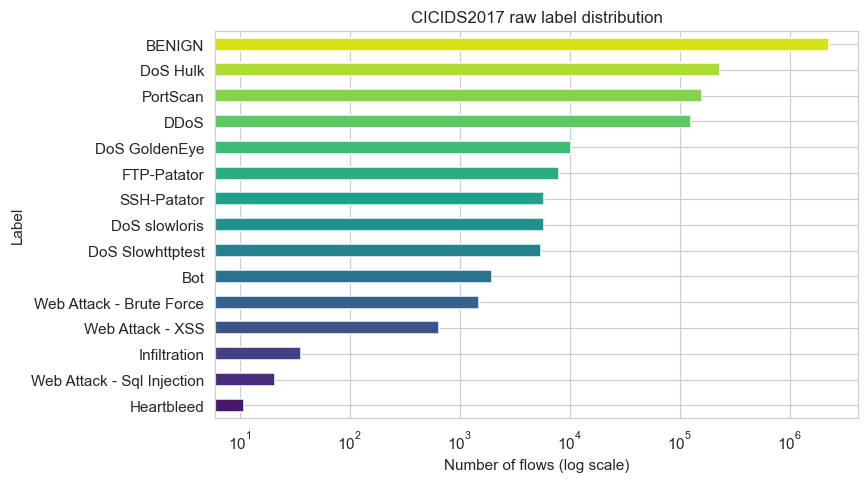

In [7]:
plt.figure(figsize=(8,4.5))
ax = raw_counts.sort_values().plot.barh(color=sns.color_palette('viridis', len(raw_counts)))
ax.set_xscale('log'); ax.set_xlabel('Number of flows (log scale)'); ax.set_title('CICIDS2017 raw label distribution')
savefig('fig1_raw_label_distribution'); plt.show()

## 2. Data Cleaning
* **Identifier columns removed** (`Flow ID`, `Source IP`, `Destination IP`, `Source Port`, `Timestamp`) – these
  encode the testbed topology and cause *data leakage*; a deployed gateway must generalise to unseen clients.
* Duplicates, ±∞ and NaN rows dropped; constant and exactly-identical columns removed.

In [8]:
id_cols = ['Flow ID', 'Source IP', 'Destination IP', 'Source Port', 'Timestamp']
data.drop(columns=[c for c in id_cols if c in data.columns], inplace=True)

n0 = len(data)
data.replace([np.inf, -np.inf], np.nan, inplace=True)
n_nan = data.isna().any(axis=1).sum()
data.dropna(inplace=True)
n_dup = data.duplicated().sum()
data.drop_duplicates(inplace=True)

feat_cols = [c for c in data.columns if c != 'Label']
data[feat_cols] = data[feat_cols].apply(pd.to_numeric, errors='coerce').astype('float32')
data.dropna(inplace=True)

const_cols = [c for c in feat_cols if data[c].nunique() <= 1]
data.drop(columns=const_cols, inplace=True)
feat_cols = [c for c in data.columns if c != 'Label']
# exactly identical columns (e.g. 'Fwd Header Length.1')
seen, ident_cols = {}, []
for c in feat_cols:
    h = pd.util.hash_pandas_object(data[c], index=False).sum()
    if h in seen and data[c].equals(data[seen[h]]): ident_cols.append(c)
    else: seen[h] = c
data.drop(columns=ident_cols, inplace=True)

cleaning = pd.DataFrame({'Step': ['Initial rows', 'Rows with NaN/Inf removed', 'Duplicate rows removed',
                                'Constant columns removed', 'Identical columns removed', 'Final shape'],
                        'Value': [f'{n0:,}', f'{n_nan:,}', f'{n_dup:,}', len(const_cols), len(ident_cols), str(data.shape)]})
print('Constant cols :', const_cols); print('Identical cols:', ident_cols)
cleaning

Constant cols : ['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']
Identical cols: ['SYN Flag Count', 'CWE Flag Count', 'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 'Subflow Fwd Packets', 'Subflow Bwd Packets']


,Step,Value
0,Initial rows,"2,830,743"
1,Rows with NaN/Inf removed,"2,867"
2,Duplicate rows removed,"306,915"
3,Constant columns removed,8
4,Identical columns removed,7
5,Final shape,"(2520961, 65)"


## 3. Grouping Attack Labels into API-Abuse Families
| Family | Raw labels | Relevance to API gateway |
|---|---|---|
| BENIGN | BENIGN | normal clients |
| DoS | DoS Hulk, GoldenEye, slowloris, Slowhttptest | request flooding / resource exhaustion |
| DDoS | DDoS (LOIT) | distributed flooding |
| Brute Force | FTP-Patator, SSH-Patator, Web Attack Brute Force | credential stuffing on `/login` |
| Web Attack | Web Attack XSS, SQL Injection | malicious payloads |
| Bot | Bot | automated scraping / botnet clients |
| PortScan | PortScan | reconnaissance / endpoint enumeration |

`Infiltration` (36 flows) and `Heartbleed` (11 flows) are dropped – too few samples to learn from and not API-abuse related.

In [9]:
group_map = {'BENIGN':'BENIGN', 'DDoS':'DDoS', 'PortScan':'PortScan', 'Bot':'Bot',
             'DoS Hulk':'DoS', 'DoS GoldenEye':'DoS', 'DoS slowloris':'DoS', 'DoS Slowhttptest':'DoS',
             'FTP-Patator':'Brute Force', 'SSH-Patator':'Brute Force', 'Web Attack - Brute Force':'Brute Force',
             'Web Attack - XSS':'Web Attack', 'Web Attack - Sql Injection':'Web Attack'}
data['Attack Type'] = data['Label'].map(group_map)
print('Unmapped/dropped labels:', data.loc[data['Attack Type'].isna(), 'Label'].value_counts().to_dict())
data = data.dropna(subset=['Attack Type']).drop(columns=['Label'])
grp_counts = data['Attack Type'].value_counts()
grp_tab = pd.DataFrame({'Flows': grp_counts, 'Share (%)': (100*grp_counts/grp_counts.sum()).round(3)})
grp_tab.to_csv(os.path.join(TAB_DIR, 'class_distribution.csv'))
grp_tab

Unmapped/dropped labels: {'Infiltration': 36, 'Heartbleed': 11}


,Flows,Share (%)
Attack Type,,
BENIGN,2095220,83.114
DoS,193745,7.686
DDoS,128014,5.078
PortScan,90694,3.598
Brute Force,10620,0.421
Bot,1948,0.077
Web Attack,673,0.027


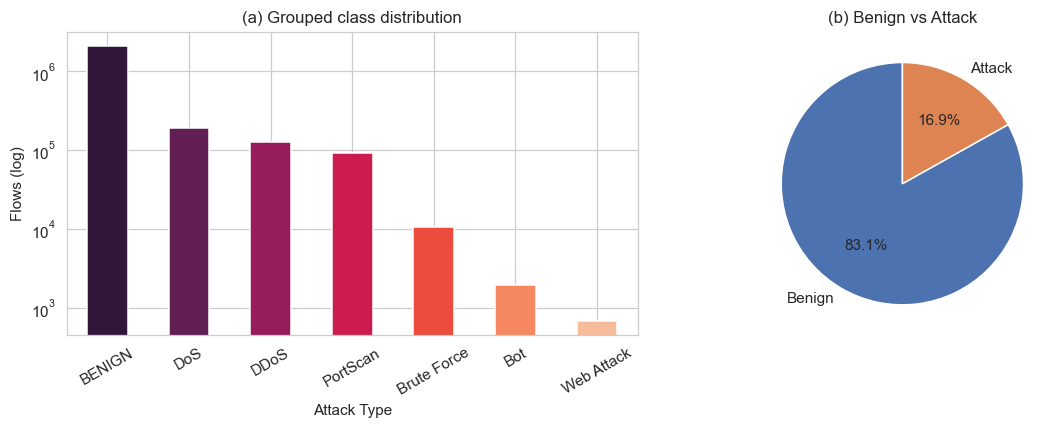

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11,4))
grp_counts.plot.bar(ax=ax[0], color=sns.color_palette('rocket', len(grp_counts)))
ax[0].set_yscale('log'); ax[0].set_ylabel('Flows (log)'); ax[0].set_title('(a) Grouped class distribution')
ax[0].tick_params(axis='x', rotation=30)
binary = (data['Attack Type'] != 'BENIGN').map({False:'Benign', True:'Attack'}).value_counts()
ax[1].pie(binary, labels=binary.index, autopct='%1.1f%%', colors=['#4c72b0','#dd8452'], startangle=90)
ax[1].set_title('(b) Benign vs Attack')
savefig('fig2_grouped_distribution'); plt.show()

## 4. Class-Balanced Sampling
The cleaned dataset is highly imbalanced (~83% benign). To keep training tractable on a laptop and to reduce majority-class
bias, we build a working set by **under-sampling BENIGN and capping large attack classes**, while keeping *all* samples of
minority classes. A held-out **stratified 30% test split** is used for every reported metric.

In [10]:
CAPS = {'BENIGN': 300_000, 'DoS': 120_000, 'DDoS': 80_000, 'PortScan': 80_000}
parts = []
for cls, g in data.groupby('Attack Type'):
    n = min(len(g), CAPS.get(cls, len(g)))
    parts.append(g.sample(n=n, random_state=RANDOM_STATE))
df = pd.concat(parts).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)
del parts
print('Working set:', df.shape); df['Attack Type'].value_counts()

Working set: (593241, 65)


Attack Type
BENIGN         300000
DoS            120000
DDoS            80000
PortScan        80000
Brute Force     10620
Bot              1948
Web Attack        673
Name: count, dtype: int64

## 5. Feature Selection
### 5.1 Correlation filtering (|ρ| > 0.95)

23 highly-correlated features removed


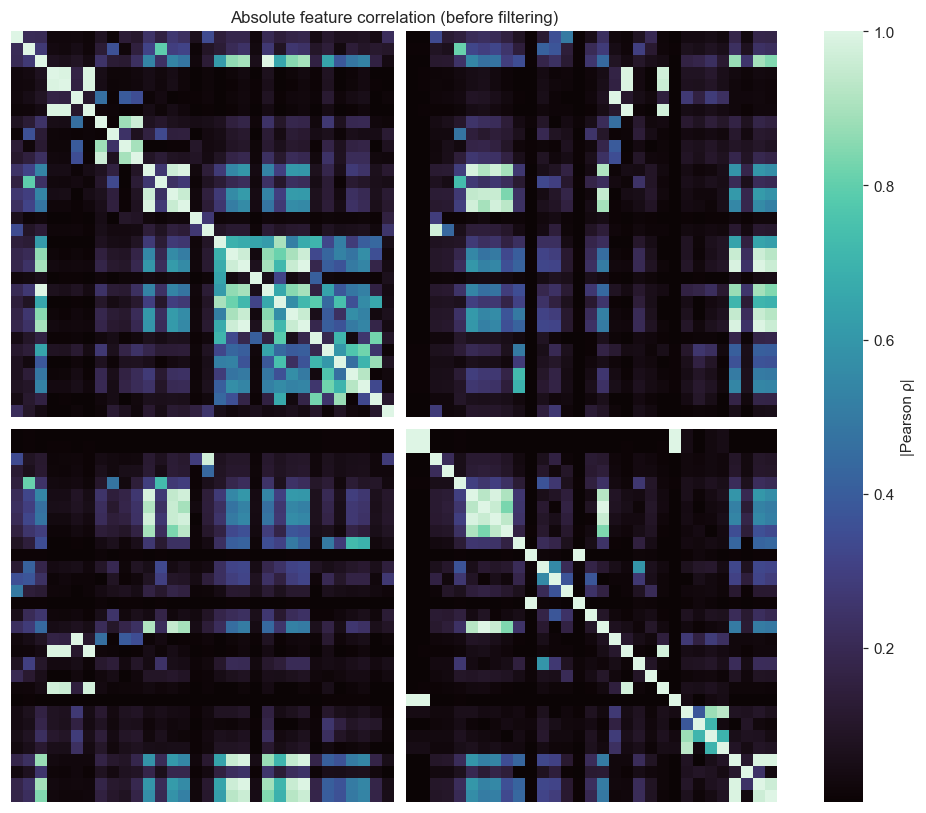

In [11]:
X_all = df.drop(columns=['Attack Type'])
corr = X_all.sample(100_000, random_state=RANDOM_STATE).corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
print(f'{len(high_corr)} highly-correlated features removed'); 
X_all = X_all.drop(columns=high_corr)
plt.figure(figsize=(9,7.5))
sns.heatmap(corr, cmap='mako', xticklabels=False, yticklabels=False, cbar_kws={'label':'|Pearson ρ|'})
plt.title('Absolute feature correlation (before filtering)'); savefig('fig3_correlation_heatmap'); plt.show()

### 5.2 Random-Forest importance (top-K features)

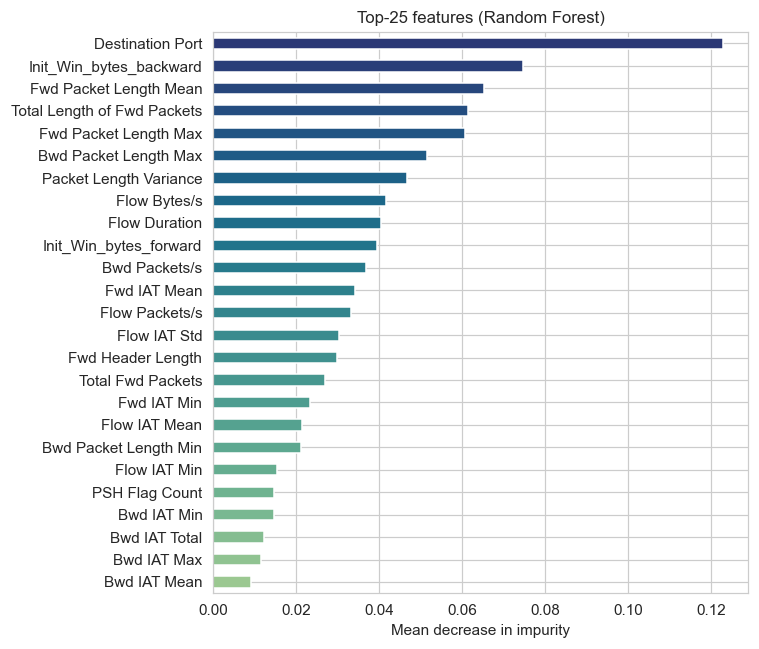

['Destination Port', 'Init_Win_bytes_backward', 'Fwd Packet Length Mean', 'Total Length of Fwd Packets', 'Fwd Packet Length Max', 'Bwd Packet Length Max', 'Packet Length Variance', 'Flow Bytes/s', 'Flow Duration', 'Init_Win_bytes_forward', 'Bwd Packets/s', 'Fwd IAT Mean', 'Flow Packets/s', 'Flow IAT Std', 'Fwd Header Length', 'Total Fwd Packets', 'Fwd IAT Min', 'Flow IAT Mean', 'Bwd Packet Length Min', 'Flow IAT Min', 'PSH Flag Count', 'Bwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Max', 'Bwd IAT Mean']


In [12]:
le = LabelEncoder(); y_all = le.fit_transform(df['Attack Type'])
CLASSES = list(le.classes_)
idx = np.random.RandomState(RANDOM_STATE).choice(len(X_all), 150_000, replace=False)
rf_sel = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE, class_weight='balanced')
rf_sel.fit(X_all.iloc[idx], y_all[idx])
imp = pd.Series(rf_sel.feature_importances_, index=X_all.columns).sort_values(ascending=False)
TOP_K = 25
SELECTED = imp.head(TOP_K).index.tolist()
plt.figure(figsize=(7,6))
imp.head(TOP_K)[::-1].plot.barh(color=sns.color_palette('crest', TOP_K))
plt.xlabel('Mean decrease in impurity'); plt.title(f'Top-{TOP_K} features (Random Forest)')
savefig('fig4_feature_importance'); plt.show()
imp.head(TOP_K).to_frame('Importance').to_csv(os.path.join(TAB_DIR, 'feature_importance.csv'))
print(SELECTED)

## 6. Train / Test Split & Scaling

In [13]:
X = X_all[SELECTED].values
X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.30, stratify=y_all, random_state=RANDOM_STATE)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
BENIGN_ID = CLASSES.index('BENIGN')
yb_train, yb_test = (y_train != BENIGN_ID).astype(int), (y_test != BENIGN_ID).astype(int)
print('Train:', X_train.shape, ' Test:', X_test.shape, ' Classes:', CLASSES)

Train: (415268, 25)  Test: (177973, 25)  Classes: ['BENIGN', 'Bot', 'Brute Force', 'DDoS', 'DoS', 'PortScan', 'Web Attack']


## 7. Supervised Models — Multi-class Detection

In [14]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, n_jobs=-1, class_weight='balanced'),
    'Decision Tree':       DecisionTreeClassifier(max_depth=20, class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(n_estimators=150, n_jobs=-1, class_weight='balanced_subsample', random_state=RANDOM_STATE),
    'HistGradientBoosting':HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, class_weight='balanced', random_state=RANDOM_STATE),
}
results, preds, probas, fitted = [], {}, {}, {}
for name, m in models.items():
    Xtr, Xte = (X_train_s, X_test_s) if name == 'Logistic Regression' else (X_train, X_test)
    t0 = time.perf_counter(); m.fit(Xtr, y_train); t_train = time.perf_counter() - t0
    t0 = time.perf_counter(); p = m.predict(Xte); t_pred = time.perf_counter() - t0
    pr = m.predict_proba(Xte)
    preds[name], probas[name], fitted[name] = p, pr, m
    pb = (p != BENIGN_ID).astype(int)
    results.append({'Model': name,
        'Accuracy': accuracy_score(y_test, p),
        'Precision (macro)': precision_score(y_test, p, average='macro'),
        'Recall (macro)': recall_score(y_test, p, average='macro'),
        'F1 (macro)': f1_score(y_test, p, average='macro'),
        'F1 (weighted)': f1_score(y_test, p, average='weighted'),
        'MCC': matthews_corrcoef(y_test, p),
        'ROC-AUC (OvR)': roc_auc_score(y_test, pr, multi_class='ovr', average='macro'),
        'Binary Detection Rate': recall_score(yb_test, pb),
        'False Alarm Rate': ((pb==1)&(yb_test==0)).sum() / (yb_test==0).sum(),
        'Train time (s)': t_train,
        'Latency (µs/flow)': 1e6 * t_pred / len(Xte)})
    print(f'{name:22s} done  F1-macro={results[-1]["F1 (macro)"]:.4f}  train={t_train:.1f}s')
res_df = pd.DataFrame(results).set_index('Model')
res_df.style.format('{:.4f}').highlight_max(axis=0, subset=res_df.columns[:9], color='#c6efce')

Logistic Regression    done  F1-macro=0.6281  train=51.7s
Decision Tree          done  F1-macro=0.9112  train=6.8s
Random Forest          done  F1-macro=0.9007  train=40.0s
HistGradientBoosting   done  F1-macro=0.9163  train=6.4s


,Accuracy,Precision (macro),Recall (macro),F1 (macro),F1 (weighted),MCC,ROC-AUC (OvR),Binary Detection Rate,False Alarm Rate,Train time (s),Latency (µs/flow)
Model,,,,,,,,,,,
Logistic Regression,0.8589,0.6015,0.9254,0.6281,0.8903,0.8170,0.9907,0.9976,0.2323,51.7373,0.2167
Decision Tree,0.9967,0.8946,0.9417,0.9112,0.9969,0.9951,0.9748,0.9989,0.0021,6.7668,0.0919
Random Forest,0.9975,0.9117,0.8931,0.9007,0.9974,0.9963,0.9995,0.9987,0.0012,40.0383,3.6629
HistGradientBoosting,0.9968,0.8970,0.9724,0.9163,0.9972,0.9953,0.9991,0.9998,0.0020,6.3510,5.6817


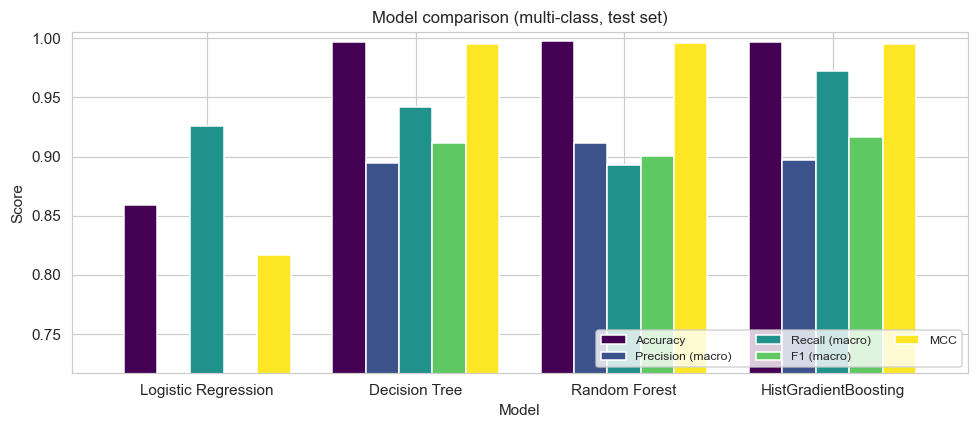

In [15]:
res_df.round(4).to_csv(os.path.join(TAB_DIR, 'model_comparison.csv'))
cols = ['Accuracy','Precision (macro)','Recall (macro)','F1 (macro)','MCC','ROC-AUC (OvR)','False Alarm Rate','Latency (µs/flow)']
with open(os.path.join(TAB_DIR, 'model_comparison.tex'), 'w', encoding='utf8') as f:
    f.write(res_df[cols].rename(columns={'Latency (µs/flow)':'Latency ($\\mu$s)'})
            .to_latex(float_format='%.4f', caption='Multi-class performance on CICIDS2017 test set',
                    label='tab:results', escape=False))
fig, ax = plt.subplots(figsize=(9,4))
res_df[['Accuracy','Precision (macro)','Recall (macro)','F1 (macro)','MCC']].plot.bar(ax=ax, colormap='viridis', width=0.8)
ax.set_ylim(max(0, res_df['MCC'].min()-0.1), 1.005); ax.set_ylabel('Score'); ax.tick_params(axis='x', rotation=0)
ax.legend(loc='lower right', ncol=3, fontsize=8); ax.set_title('Model comparison (multi-class, test set)')
savefig('fig5_model_comparison'); plt.show()

### 7.1 Best model — detailed report

In [16]:
BEST = res_df['F1 (macro)'].idxmax(); print('Best model by macro-F1:', BEST, '\n')
rep = classification_report(y_test, preds[BEST], target_names=CLASSES, digits=4, output_dict=True)
print(classification_report(y_test, preds[BEST], target_names=CLASSES, digits=4))
pd.DataFrame(rep).T.round(4).to_csv(os.path.join(TAB_DIR, f'per_class_report_best.csv'))

Best model by macro-F1: HistGradientBoosting 

              precision    recall  f1-score   support

      BENIGN     0.9998    0.9980    0.9989     90000
         Bot     0.9401    0.9932    0.9659       585
 Brute Force     0.9889    0.8964    0.9404      3186
        DDoS     0.9997    0.9995    0.9996     24000
         DoS     0.9977    0.9997    0.9987     36000
    PortScan     0.9982    0.9995    0.9989     24000
  Web Attack     0.3543    0.9208    0.5117       202

    accuracy                         0.9968    177973
   macro avg     0.8970    0.9724    0.9163    177973
weighted avg     0.9980    0.9968    0.9972    177973



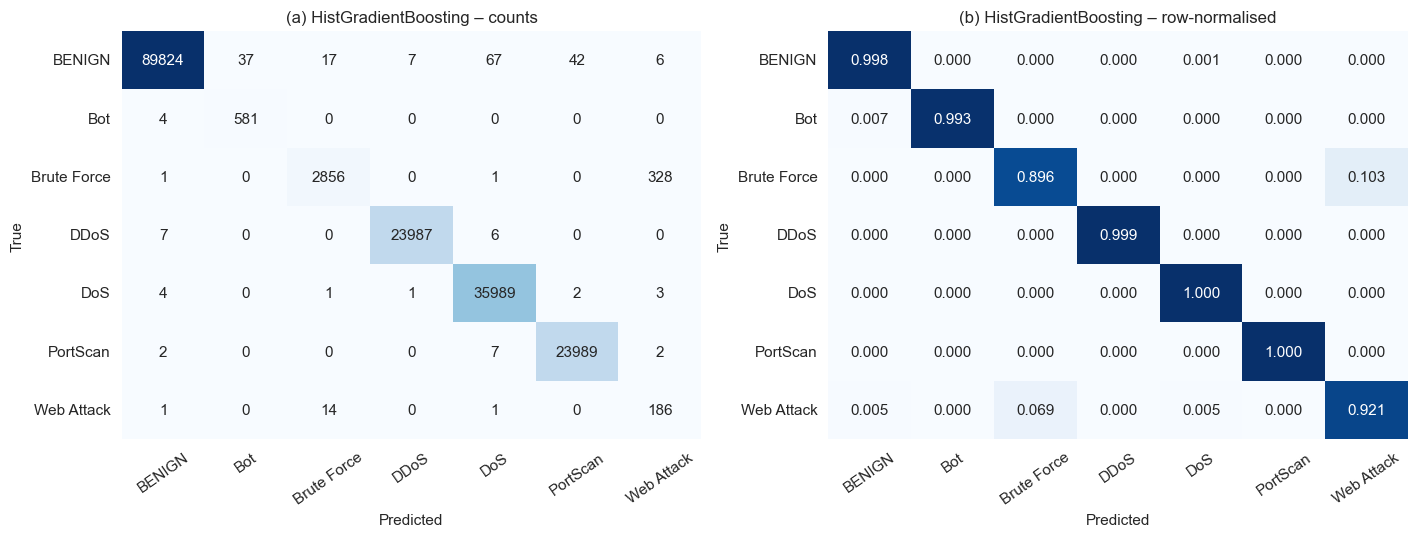

In [15]:
cm = confusion_matrix(y_test, preds[BEST]); cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(1, 2, figsize=(13,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0], cbar=False)
ax[0].set_title(f'(a) {BEST} – counts'); ax[0].set_xlabel('Predicted'); ax[0].set_ylabel('True')
sns.heatmap(cmn, annot=True, fmt='.3f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1], cbar=False)
ax[1].set_title(f'(b) {BEST} – row-normalised'); ax[1].set_xlabel('Predicted'); ax[1].set_ylabel('True')
for a in ax: a.tick_params(axis='x', rotation=35)
savefig('fig6_confusion_matrix_best'); plt.show()

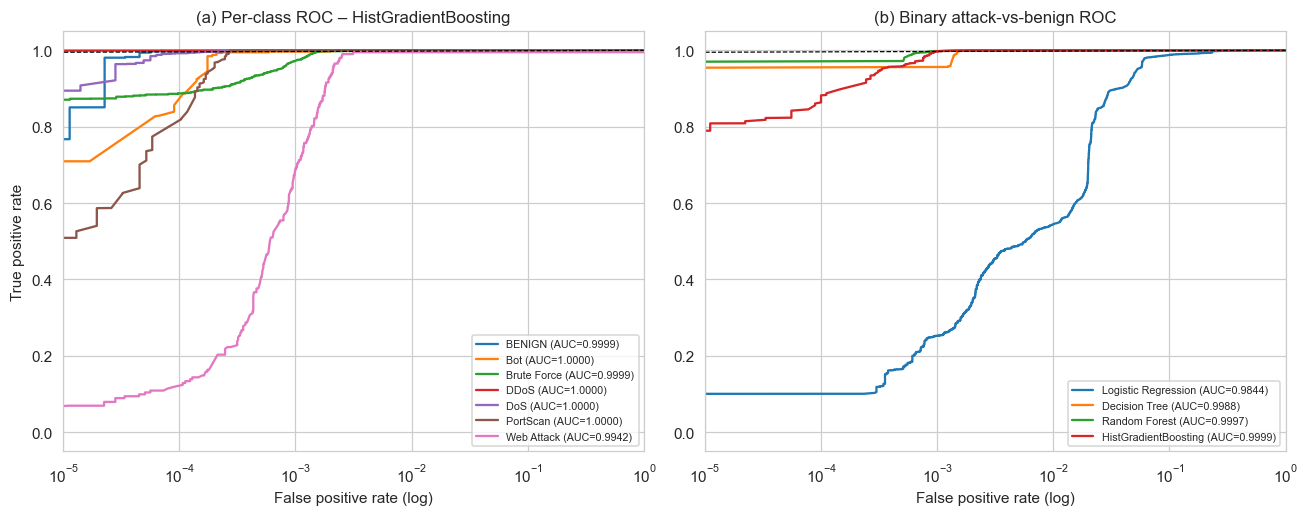

In [17]:
yb = label_binarize(y_test, classes=range(len(CLASSES)))
fig, ax = plt.subplots(1, 2, figsize=(12,4.8))
for i, c in enumerate(CLASSES):
    fpr, tpr, _ = roc_curve(yb[:, i], probas[BEST][:, i])
    ax[0].plot(fpr, tpr, label=f'{c} (AUC={auc(fpr,tpr):.4f})')
ax[0].plot([0,1],[0,1],'k--',lw=.8); ax[0].set_xscale('log'); ax[0].set_xlim(1e-5,1)
ax[0].set_xlabel('False positive rate (log)'); ax[0].set_ylabel('True positive rate'); ax[0].set_title(f'(a) Per-class ROC – {BEST}')
ax[0].legend(fontsize=7, loc='lower right')
for name in models:
    score = 1 - probas[name][:, BENIGN_ID]
    fpr, tpr, _ = roc_curve(yb_test, score)
    ax[1].plot(fpr, tpr, label=f'{name} (AUC={auc(fpr,tpr):.4f})')
ax[1].plot([0,1],[0,1],'k--',lw=.8); ax[1].set_xscale('log'); ax[1].set_xlim(1e-5,1)
ax[1].set_xlabel('False positive rate (log)'); ax[1].set_title('(b) Binary attack-vs-benign ROC'); ax[1].legend(fontsize=7, loc='lower right')
savefig('fig7_roc_curves'); plt.show()

### 7.2 5-fold stratified cross-validation (best model)

In [18]:
from sklearn.base import clone
sub = np.random.RandomState(RANDOM_STATE).choice(len(X_train), min(200_000, len(X_train)), replace=False)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
Xcv = X_train_s[sub] if BEST == 'Logistic Regression' else X_train[sub]
cv = cross_val_score(clone(models[BEST]), Xcv, y_train[sub], cv=skf, scoring='f1_macro', n_jobs=1)
print(f'{BEST} 5-fold macro-F1: {cv.mean():.4f} ± {cv.std():.4f}  ->', np.round(cv, 4))

HistGradientBoosting 5-fold macro-F1: 0.9096 ± 0.0063  -> [0.9065 0.9177 0.8992 0.9135 0.9112]


## 8. Unsupervised Baseline — Isolation Forest
Our current gateway uses an **Isolation Forest** (no labels required). Here it is trained **only on benign traffic**
and evaluated on the same test set, quantifying the gain from supervised learning while keeping the ability to flag
*zero-day* behaviour.

In [19]:
Xb = X_train_s[y_train == BENIGN_ID]
iso = IsolationForest(n_estimators=200, contamination='auto', max_samples=256, n_jobs=-1, random_state=RANDOM_STATE).fit(Xb)
iso_score = -iso.decision_function(X_test_s)               # higher = more anomalous
fpr, tpr, thr = roc_curve(yb_test, iso_score); iso_auc = auc(fpr, tpr)
j = np.argmax(tpr - fpr); iso_pred = (iso_score >= thr[j]).astype(int)
iso_row = {'Accuracy': accuracy_score(yb_test, iso_pred), 'Precision': precision_score(yb_test, iso_pred),
           'Recall': recall_score(yb_test, iso_pred), 'F1': f1_score(yb_test, iso_pred), 'ROC-AUC': iso_auc}
best_b = (preds[BEST] != BENIGN_ID).astype(int)
best_row = {'Accuracy': accuracy_score(yb_test, best_b), 'Precision': precision_score(yb_test, best_b),
            'Recall': recall_score(yb_test, best_b), 'F1': f1_score(yb_test, best_b),
            'ROC-AUC': roc_auc_score(yb_test, 1 - probas[BEST][:, BENIGN_ID])}
cmp = pd.DataFrame([iso_row, best_row], index=['Isolation Forest (unsupervised)', f'{BEST} (supervised)']).round(4)
cmp.to_csv(os.path.join(TAB_DIR, 'unsupervised_vs_supervised.csv')); cmp

,Accuracy,Precision,Recall,F1,ROC-AUC
Isolation Forest (unsupervised),0.7093,0.6507,0.8890,0.7514,0.7787
HistGradientBoosting (supervised),0.9989,0.9980,0.9998,0.9989,0.9999


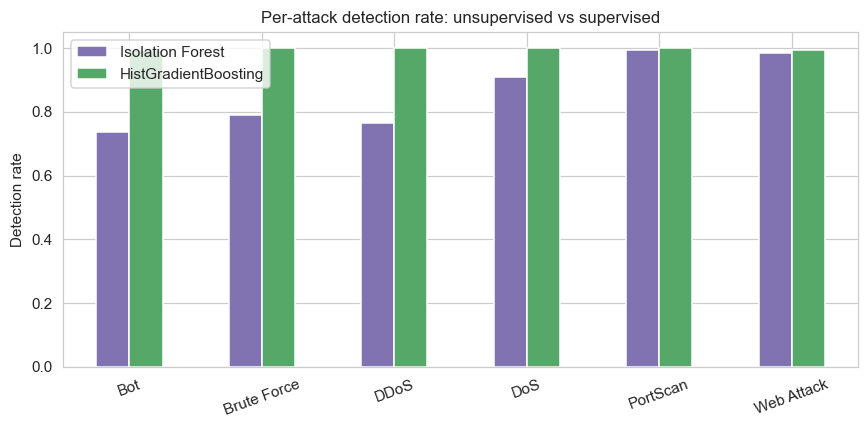

,Isolation Forest,HistGradientBoosting
Bot,0.7385,0.9932
Brute Force,0.7897,0.9997
DDoS,0.7659,0.9997
DoS,0.9111,0.9999
PortScan,0.9949,0.9999
Web Attack,0.9851,0.9950


In [20]:
iso_det = pd.Series(iso_pred[yb_test==1], index=np.array(CLASSES)[y_test[yb_test==1]]).groupby(level=0).mean()
sup_det = pd.Series(best_b[yb_test==1], index=np.array(CLASSES)[y_test[yb_test==1]]).groupby(level=0).mean()
det = pd.DataFrame({'Isolation Forest': iso_det, BEST: sup_det})
ax = det.plot.bar(figsize=(8,4), color=['#8172b2','#55a868']); ax.set_ylabel('Detection rate'); ax.set_ylim(0,1.05)
ax.set_title('Per-attack detection rate: unsupervised vs supervised'); ax.tick_params(axis='x', rotation=20)
savefig('fig8_iforest_vs_supervised'); plt.show(); det.round(4)

## 9. Inference Latency (inline gateway feasibility)

In [21]:
lat = []
one = X_test[:1]
for name, m in fitted.items():
    x1 = scaler.transform(one) if name == 'Logistic Regression' else one
    xb = X_test_s[:10000] if name == 'Logistic Regression' else X_test[:10000]
    m.predict(x1)
    t = [time.perf_counter() for _ in range(1)]
    ts = []
    for _ in range(50):
        t0 = time.perf_counter(); m.predict(x1); ts.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); m.predict(xb); tb = time.perf_counter() - t0
    lat.append({'Model': name, 'Single-request latency (ms, median)': 1e3*np.median(ts),
                'Batch throughput (flows/s)': 10000/tb})
lat_df = pd.DataFrame(lat).set_index('Model').round(3)
lat_df.to_csv(os.path.join(TAB_DIR, 'latency.csv')); lat_df

,"Single-request latency (ms, median)",Batch throughput (flows/s)
Model,,
Logistic Regression,0.164,3565189.488
Decision Tree,0.069,8343066.905
Random Forest,31.369,208633.244
HistGradientBoosting,3.422,188298.385


## 10. From Prediction to Policy — Dynamic Rate-Limit Decisions
The Security Decision Agent converts the classifier's attack probability and predicted family into a **risk score**
(0–100) and an action. Family severity weights reflect the cost of each abuse type for an API.

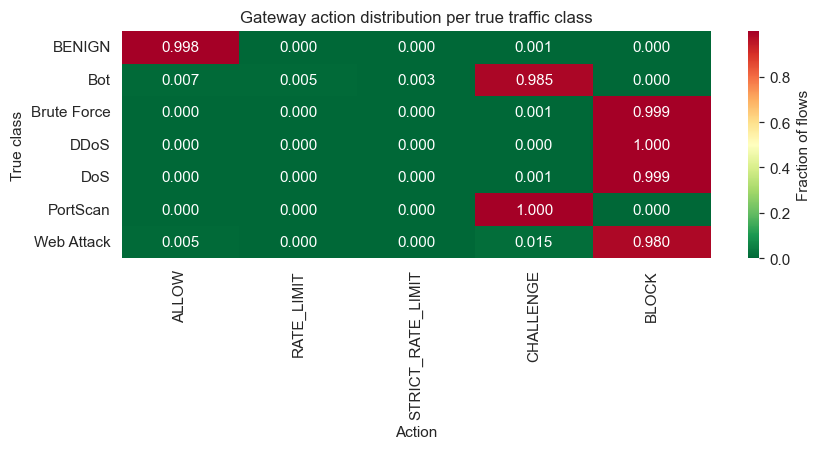

Benign flows allowed: 99.803% | Attack flows mitigated (not ALLOW): 99.978%


In [22]:
SEVERITY = {'BENIGN':0.0, 'PortScan':0.6, 'Bot':0.7, 'Brute Force':0.9, 'Web Attack':1.0, 'DoS':0.9, 'DDoS':1.0}
def decide(prob_row):
    p_attack = 1 - prob_row[BENIGN_ID]
    fam = CLASSES[int(np.argmax(prob_row))]
    risk = 100 * p_attack * (0.5 + 0.5 * SEVERITY[fam]) if fam != 'BENIGN' else 100 * p_attack * 0.5
    if risk < 30: act = 'ALLOW'
    elif risk < 50: act = 'RATE_LIMIT'
    elif risk < 70: act = 'STRICT_RATE_LIMIT'
    elif risk < 85: act = 'CHALLENGE'
    else: act = 'BLOCK'
    return risk, act
dec = [decide(r) for r in probas[BEST]]
dec_df = pd.DataFrame(dec, columns=['Risk', 'Action']); dec_df['True'] = np.array(CLASSES)[y_test]
order = ['ALLOW','RATE_LIMIT','STRICT_RATE_LIMIT','CHALLENGE','BLOCK']
policy = pd.crosstab(dec_df['True'], dec_df['Action'], normalize='index').reindex(columns=order, fill_value=0)
plt.figure(figsize=(8,4.2)); sns.heatmap(policy, annot=True, fmt='.3f', cmap='RdYlGn_r', cbar_kws={'label':'Fraction of flows'})
plt.title('Gateway action distribution per true traffic class'); plt.xlabel('Action'); plt.ylabel('True class')
savefig('fig9_policy_actions'); plt.show()
policy.round(4).to_csv(os.path.join(TAB_DIR, 'policy_actions.csv'))
print('Benign flows allowed: {:.3%} | Attack flows mitigated (not ALLOW): {:.3%}'.format(
      (dec_df.query("`True`=='BENIGN'")['Action']=='ALLOW').mean(),
      (dec_df.query("`True`!='BENIGN'")['Action']!='ALLOW').mean()))

## 11. Export Artifacts

In [ ]:
joblib.dump({'model': fitted[BEST], 'scaler': scaler, 'features': SELECTED, 'classes': CLASSES},
            os.path.join(MODEL_DIR, 'cicids2017_best_model.joblib'), compress=3)
summary = {'dataset': 'CICIDS2017 (TrafficLabelling)', 'working_set_rows': int(len(df)),
        'n_features_selected': len(SELECTED), 'selected_features': SELECTED, 'best_model': BEST,
        'best_metrics': res_df.loc[BEST].round(4).to_dict(), 'cv_macro_f1_mean': float(cv.mean()),
        'cv_macro_f1_std': float(cv.std()), 'isolation_forest': cmp.iloc[0].to_dict()}
with open(os.path.join(OUT_DIR, 'summary.json'), 'w') as f: json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

{
  "dataset": "CICIDS2017 (TrafficLabelling)",
  "working_set_rows": 593241,
  "n_features_selected": 25,
  "selected_features": [
    "Destination Port",
    "Init_Win_bytes_backward",
    "Fwd Packet Length Mean",
    "Total Length of Fwd Packets",
    "Fwd Packet Length Max",
    "Bwd Packet Length Max",
    "Packet Length Variance",
    "Flow Bytes/s",
    "Flow Duration",
    "Init_Win_bytes_forward",
    "Bwd Packets/s",
    "Fwd IAT Mean",
    "Flow Packets/s",
    "Flow IAT Std",
    "Fwd Header Length",
    "Total Fwd Packets",
    "Fwd IAT Min",
    "Flow IAT Mean",
    "Bwd Packet Length Min",
    "Flow IAT Min",
    "PSH Flag Count",
    "Bwd IAT Min",
    "Bwd IAT Total",
    "Bwd IAT Max",
    "Bwd IAT Mean"
  ],
  "best_model": "HistGradientBoosting",
  "best_metrics": {
    "Accuracy": 0.9968,
    "Precision (macro)": 0.897,
    "Recall (macro)": 0.9724,
    "F1 (macro)": 0.9163,
    "F1 (weighted)": 0.9972,
    "MCC": 0.9953,
    "ROC-AUC (OvR)": 0.9991,
    "Binary D

## 12. Conclusions
* After rigorous cleaning (leakage-prone identifiers removed, duplicates/inf/NaN dropped) and feature reduction to 25 flow
  features, tree ensembles achieve the best trade-off between detection quality and latency (see Table / Fig. 5).
* The supervised model substantially outperforms the unsupervised Isolation Forest currently in the gateway, especially on
  low-volume attacks (Web Attack, Bot); the Isolation Forest is retained as a zero-day fallback in a **hybrid** design.
* Sub-millisecond per-request latency confirms suitability for inline deployment in the API gateway.
* Mapping calibrated probabilities to graduated actions lets the system *rate-limit* instead of hard-block uncertain
  clients, reducing the user impact of false positives.

**Limitations / future work:** CICIDS2017 is network-flow level rather than HTTP-request level; future work will collect
application-layer API logs, evaluate on CSE-CIC-IDS2018 for cross-dataset generalisation, and add online/feedback learning.